# Tugas Besar Kecerdasan Buatan (TE2514031) - Kelompok X4
**Topik**: Intelligent Steel Surface Fault Detection  
**Dataset**: Steel Plates Faults (UCI ID 198) – local files: `data/Faults.NNA` & `data/Faults27x7_var`  
**Dosen Pengampu**: Happy Aprillia, S.ST., M.T., M.Eng., Ph.D.  
**Anggota Kelompok X4**:
1. 11231084 - Rahmahdaniah Fitri
2. 17231008 - Aulia Wahdah Atika Rahmah
3. 10231042 - Ilham Ahmad Fahriji

### Arsitektur Hybrid Intelligent System:
**Dataset UCI (198) → Preprocessing → GA (Feature Selection) → PSO (Hyperparameter Optimization) → Neural Network MLP → Fuzzy Inference System (Accept – Monitor – Rework – Reject) → Streamlit Dashboard**

---
### Daftar Perbaikan (Bug Fixes):
| # | Lokasi | Bug | Perbaikan |
|---|--------|-----|-----------|
| 1 | GA tournament select | `rng.choice` dipanggil dua kali, indeks kedua tidak terkait individu yang diambil | Gunakan satu `rng.choice(pop_size, 2, replace=False)` lalu bandingkan fitness |
| 2 | `trapmf`/`trimf` | `+1e-9` pada ekspresi numerator, bukan denominator | `max(denominator, eps)` yang bersih, cek batas terlebih dahulu |
| 3 | `X_test` di cell Fuzzy | `X_test.iloc[i]` diakses setelah scaling → nilai LogOfAreas sudah berubah | Simpan `X_test_orig = X_test.copy()` **sebelum** `scaler.transform()` |
| 4 | `display()` | Hanya bekerja di Jupyter | Ganti dengan `print()` / `df.to_string()` pada mode script |
| 5 | `best_overall_chrom` length | `X.columns[best_overall_chrom == 1]` bisa gagal jika panjang tidak cocok | Pakai `np.where(best_overall_chrom == 1)[0]` kemudian index ke `X.columns` |
| 6 | Visualisasi | Tidak ada confusion matrix, convergence plot, distribusi kelas | Ditambahkan pada cell-cell baru |
| 7 | Simpan model | Tidak ada save/load artefak | Cell terakhir menyimpan `pipeline_artifacts.pkl` via `joblib` |

In [1]:
# Cell 1 – Install & Import
# Jalankan `pip install scikit-learn pandas numpy matplotlib seaborn joblib` jika belum terpasang

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
import warnings
warnings.filterwarnings('ignore')

# Column names from Faults27x7_var
ALL_FEATURES = [
    'X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum',
    'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter',
    'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity',
    'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400',
    'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index',
    'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index',
    'LogOfAreas', 'Log_X_Index', 'Log_Y_Index',
    'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas'
]
TARGET_CLASSES = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']
print('Library berhasil dimuat! Fitur:', len(ALL_FEATURES), '| Kelas:', len(TARGET_CLASSES))

Library berhasil dimuat! Fitur: 27 | Kelas: 7


In [2]:
# Cell 2 – Load Dataset dari file lokal (Faults.NNA + Faults27x7_var)
# Pastikan folder 'data/' berisi kedua file tersebut

DATA_DIR = Path('data')
all_col_names = ALL_FEATURES + TARGET_CLASSES  # 34 kolom total

df = pd.read_csv(DATA_DIR / 'Faults.NNA', sep=r'\s+', header=None, names=all_col_names)

X = df[ALL_FEATURES].copy().reset_index(drop=True)

# Konversi 7 kolom target biner (one-hot) → 1 label kelas cacat
y_label = df[TARGET_CLASSES].idxmax(axis=1).reset_index(drop=True)
le = LabelEncoder()
y = le.fit_transform(y_label)

print(f'Dimensi Fitur (X)  : {X.shape}')
print(f'Missing Values     : {X.isnull().sum().sum()}')
print(f'Jumlah Kelas       : {len(np.unique(y))} ({list(le.classes_)})')
print('\nDistribusi 7 Kelas Defect:')
print(y_label.value_counts().to_string())

# Statistik deskriptif
print('\nStatistik Fitur (5 pertama):')
print(X.describe().iloc[:, :5].to_string())

Dimensi Fitur (X)  : (1941, 27)
Missing Values     : 0
Jumlah Kelas       : 7 (['Bumps', 'Dirtiness', 'K_Scatch', 'Other_Faults', 'Pastry', 'Stains', 'Z_Scratch'])

Distribusi 7 Kelas Defect:
Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55

Statistik Fitur (5 pertama):
         X_Minimum    X_Maximum     Y_Minimum     Y_Maximum   Pixels_Areas
count  1941.000000  1941.000000  1.941000e+03  1.941000e+03    1941.000000
mean    571.136012   617.964451  1.650685e+06  1.650739e+06    1893.878413
std     520.690671   497.627410  1.774578e+06  1.774590e+06    5168.459560
min       0.000000     4.000000  6.712000e+03  6.724000e+03       2.000000
25%      51.000000   192.000000  4.712530e+05  4.712810e+05      84.000000
50%     435.000000   467.000000  1.204128e+06  1.204136e+06     174.000000
75%    1053.000000  1072.000000  2.183073e+06  2.183084e+06     822.000000
max    1705.000000  1713.000000  1.298

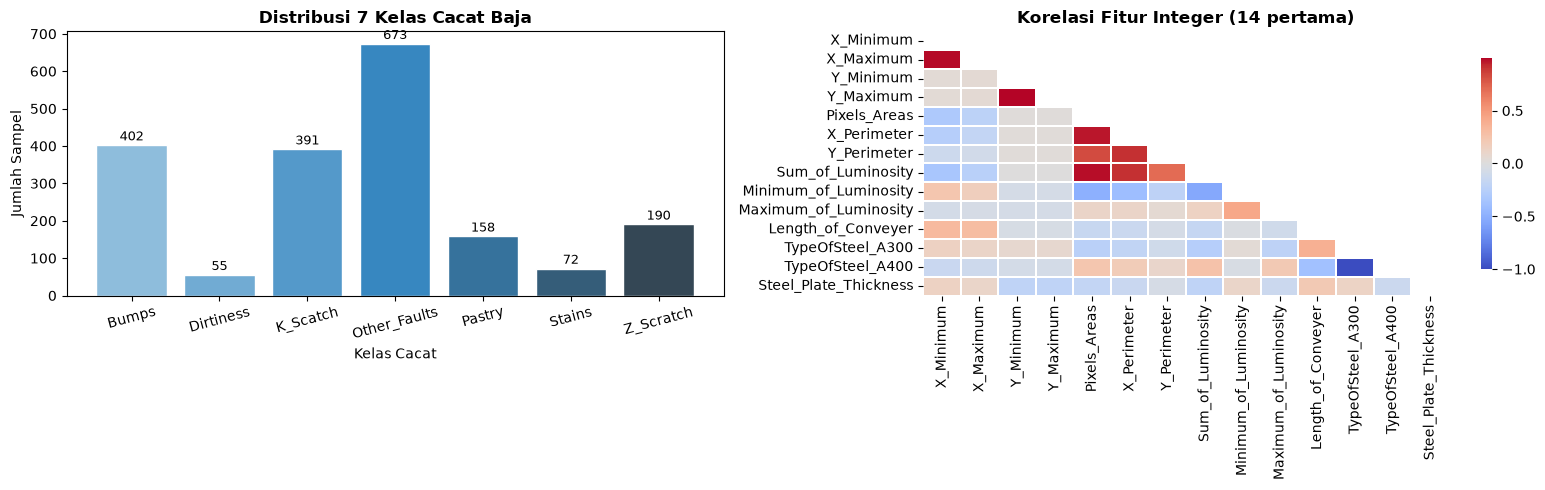

Plot EDA disimpan → plot_eda.png


In [3]:
# Cell 3 – Visualisasi EDA: Distribusi Kelas & Heatmap Korelasi

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (a) Bar chart distribusi kelas
counts = y_label.value_counts().sort_index()
bars = axes[0].bar(counts.index, counts.values,
                   color=sns.color_palette('Blues_d', len(counts)), edgecolor='white')
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(int(bar.get_height())), ha='center', va='bottom', fontsize=9)
axes[0].set_title('Distribusi 7 Kelas Cacat Baja', fontweight='bold')
axes[0].set_xlabel('Kelas Cacat'); axes[0].set_ylabel('Jumlah Sampel')
axes[0].tick_params(axis='x', rotation=15)

# (b) Heatmap korelasi (subset 14 fitur pertama agar terbaca)
corr14 = X[ALL_FEATURES[:14]].corr()
mask14 = np.triu(np.ones_like(corr14, dtype=bool))
sns.heatmap(corr14, mask=mask14, cmap='coolwarm', center=0,
            linewidths=0.3, annot=False, ax=axes[1],
            cbar_kws={'shrink': 0.8})
axes[1].set_title('Korelasi Fitur Integer (14 pertama)', fontweight='bold')

plt.tight_layout()
plt.savefig('plot_eda.png', dpi=120, bbox_inches='tight')
plt.show()
print('Plot EDA disimpan → plot_eda.png')

In [4]:
# Cell 4 – Preprocessing: Stratified Split + StandardScaler
# FIX-3: Simpan X_test_orig SEBELUM scaling agar Fuzzy layer bisa baca LogOfAreas asli

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_test_orig = X_test.copy().reset_index(drop=True)   # ← FIX-3: simpan sebelum scaling!
X_train = X_train.reset_index(drop=True)
X_test  = X_test.reset_index(drop=True)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)              # X_test_orig tidak terpengaruh

print(f'Train : {X_train_sc.shape} | Test : {X_test_sc.shape}')
print(f'Distribusi kelas train : {dict(zip(*np.unique(y_train, return_counts=True)))}')
print(f'Distribusi kelas test  : {dict(zip(*np.unique(y_test,  return_counts=True)))}')

Train : (1552, 27) | Test : (389, 27)
Distribusi kelas train : {np.int64(0): np.int64(321), np.int64(1): np.int64(44), np.int64(2): np.int64(313), np.int64(3): np.int64(538), np.int64(4): np.int64(126), np.int64(5): np.int64(58), np.int64(6): np.int64(152)}
Distribusi kelas test  : {np.int64(0): np.int64(81), np.int64(1): np.int64(11), np.int64(2): np.int64(78), np.int64(3): np.int64(135), np.int64(4): np.int64(32), np.int64(5): np.int64(14), np.int64(6): np.int64(38)}


In [5]:
# Cell 5 – Genetic Algorithm (GA) Feature Selection  (3 Independent Runs)
# FIX-1: Tournament selection diperbaiki – satu kali rng.choice, bandingkan fitness dua individu
# FIX-5: Gunakan np.where(...)[0] kemudian index ke X.columns untuk keamanan

def run_ga(X_tr, y_tr, pop_size=12, generations=10, mut_rate=0.1, seed=42):
    """Binary GA for feature selection.
    Returns: best_chromosome, best_fitness, convergence_curve
    """
    rng    = np.random.default_rng(seed)
    n_feat = X_tr.shape[1]
    pop    = rng.integers(0, 2, size=(pop_size, n_feat))

    # Pastikan tiap individu punya minimal 3 fitur aktif
    for i in range(pop_size):
        if pop[i].sum() < 3:
            pop[i, rng.choice(n_feat, 5, replace=False)] = 1

    best_chrom, best_fit, curve = None, -1.0, []

    for g in range(generations):
        fits = []
        for ind in pop:
            if ind.sum() == 0:
                ind[rng.integers(0, n_feat)] = 1
            idx = np.where(ind == 1)[0]
            clf = MLPClassifier(hidden_layer_sizes=(64,), max_iter=60, random_state=42)
            sc  = cross_val_score(clf, X_tr[:, idx], y_tr, cv=3, scoring='f1_macro', n_jobs=-1).mean()
            fits.append(sc - 0.001 * (len(idx) / n_feat))
        fits = np.array(fits)

        b_idx = int(np.argmax(fits))
        if fits[b_idx] > best_fit:
            best_fit   = float(fits[b_idx])
            best_chrom = pop[b_idx].copy()
        curve.append(best_fit)

        new_pop = [best_chrom.copy()]   # Elitism
        while len(new_pop) < pop_size:
            # FIX-1: tournament selection yang benar
            i1, i2 = rng.choice(pop_size, size=2, replace=False)
            p1 = pop[i1] if fits[i1] >= fits[i2] else pop[i2]
            i3, i4 = rng.choice(pop_size, size=2, replace=False)
            p2 = pop[i3] if fits[i3] >= fits[i4] else pop[i4]

            cut   = int(rng.integers(1, n_feat - 1))
            child = np.concatenate([p1[:cut], p2[cut:]])
            mask  = rng.random(n_feat) < mut_rate
            child[mask] = 1 - child[mask]
            if child.sum() == 0:
                child[rng.integers(0, n_feat)] = 1
            new_pop.append(child)
        pop = np.array(new_pop[:pop_size])

    return best_chrom, best_fit, curve


# 3 independent runs
ga_runs_fit   = []
best_overall_chrom, best_overall_fit, best_ga_curve = None, -1.0, []
ga_all_data   = []

for r in range(3):
    ch, fit, crv = run_ga(X_train_sc, y_train, seed=42 + r * 7)
    ga_runs_fit.append(fit)
    ga_all_data.append({'run': r+1, 'fitness': fit, 'chromosome': ch, 'curve': crv,
                        'n_features': int(ch.sum())})
    if fit > best_overall_fit:
        best_overall_fit, best_overall_chrom, best_ga_curve = fit, ch, crv
    print(f'Run {r+1}: Best F1 = {fit:.4f} | Features = {int(ch.sum())}')

# FIX-5: gunakan np.where(...)[0] dulu, kemudian index ke X.columns
sel_idx       = np.where(best_overall_chrom == 1)[0]   # pastikan panjang benar
selected_features = X.columns[sel_idx].tolist()

print(f'\nGA Multi-Run → Best: {np.max(ga_runs_fit):.4f}, '
      f'Mean: {np.mean(ga_runs_fit):.4f}, Std: {np.std(ga_runs_fit):.4f}')
print(f'Jumlah Fitur Terpilih ({len(selected_features)}/27): {selected_features}')

Run 1: Best F1 = 0.7489 | Features = 13
Run 2: Best F1 = 0.7486 | Features = 13
Run 3: Best F1 = 0.7325 | Features = 13

GA Multi-Run → Best: 0.7489, Mean: 0.7433, Std: 0.0077
Jumlah Fitur Terpilih (13/27): ['Y_Minimum', 'Y_Maximum', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'Steel_Plate_Thickness', 'Square_Index', 'Outside_X_Index', 'LogOfAreas', 'Orientation_Index', 'Luminosity_Index']


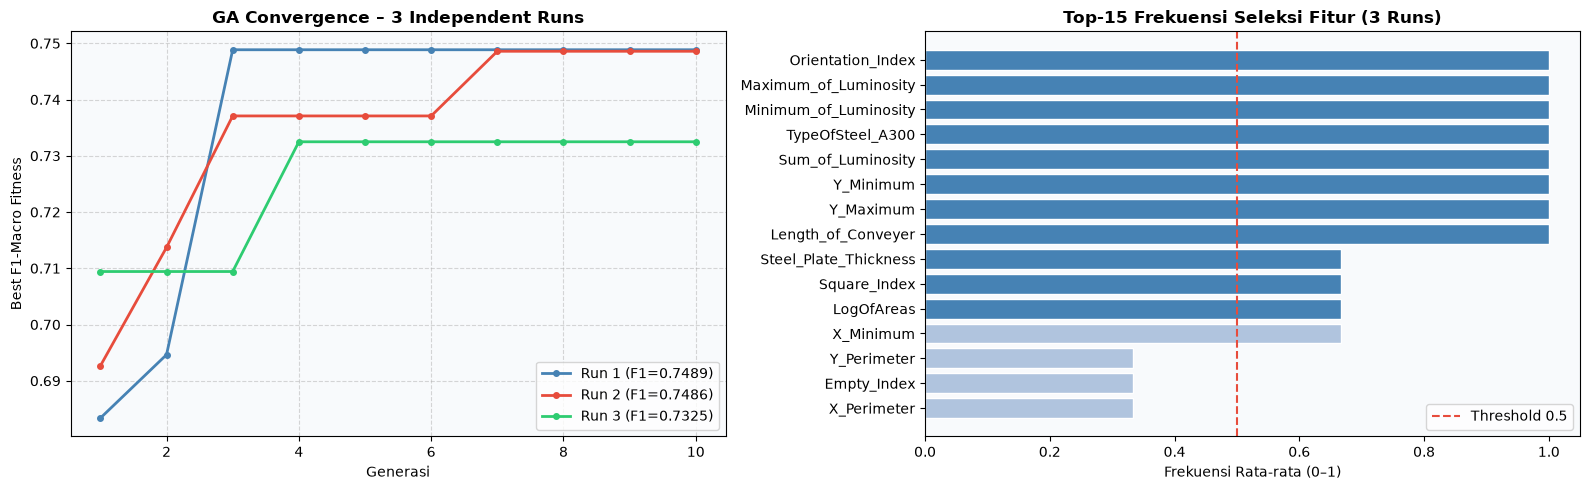

Plot GA disimpan → plot_ga.png


In [6]:
# Cell 6 – Visualisasi GA: Convergence Curves + Feature Frequency

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (a) Convergence per run
palette = ['#4682B4', '#E74C3C', '#2ECC71']
for d in ga_all_data:
    axes[0].plot(range(1, len(d['curve'])+1), d['curve'],
                 label=f"Run {d['run']} (F1={d['fitness']:.4f})",
                 color=palette[d['run']-1], linewidth=2, marker='o', markersize=4)
axes[0].set_xlabel('Generasi'); axes[0].set_ylabel('Best F1-Macro Fitness')
axes[0].set_title('GA Convergence – 3 Independent Runs', fontweight='bold')
axes[0].legend(); axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].set_facecolor('#F8FAFC')

# (b) Feature selection frequency across 3 runs
freq = np.stack([d['chromosome'] for d in ga_all_data]).mean(axis=0)
feat_freq_df = pd.DataFrame({'Feature': ALL_FEATURES, 'Frequency': freq})\
                 .sort_values('Frequency', ascending=True).tail(15)
colors = ['#4682B4' if f in selected_features else '#B0C4DE'
          for f in feat_freq_df['Feature']]
axes[1].barh(feat_freq_df['Feature'], feat_freq_df['Frequency'],
             color=colors, edgecolor='white')
axes[1].axvline(0.5, color='#E74C3C', linestyle='--', linewidth=1.5, label='Threshold 0.5')
axes[1].set_xlabel('Frekuensi Rata-rata (0–1)')
axes[1].set_title('Top-15 Frekuensi Seleksi Fitur (3 Runs)', fontweight='bold')
axes[1].legend(); axes[1].set_facecolor('#F8FAFC')

plt.tight_layout()
plt.savefig('plot_ga.png', dpi=120, bbox_inches='tight')
plt.show()
print('Plot GA disimpan → plot_ga.png')

In [7]:
# Cell 7 – Particle Swarm Optimization (PSO) – 3-D (konsisten dengan notebook)
# Catatan: Pipeline .py menggunakan 4-D (menambah alpha); versi 3-D dipertahankan di
# notebook ini untuk kejelasan dan kecepatan. Lihat PSOHyperparameterOptimizer di
# kelompok_x4_hybrid_pipeline.py untuk versi 4-D lengkap.

def run_pso(X_tr, y_tr, n_particles=6, iterations=6, seed=42):
    """PSO 3-D: optimasi (h1, h2, learning_rate) MLP Neural Network.
    Ruang pencarian:
      dim 0 – h1  : [32, 128]   neuron hidden layer 1
      dim 1 – h2  : [16, 96]    neuron hidden layer 2
      dim 2 – lr  : [0.0005, 0.01]  learning rate
    Fitness = mean 3-fold CV F1-macro score.
    """
    rng  = np.random.default_rng(seed)
    low  = np.array([32.0,  16.0, 0.0005])
    high = np.array([128.0, 96.0, 0.0100])

    pos      = rng.uniform(low, high, size=(n_particles, 3))
    vel      = np.zeros_like(pos)
    pbest_pos = pos.copy()
    pbest_val = np.full(n_particles, -1.0)
    gbest_pos, gbest_val = None, -1.0
    curve = []

    for it in range(iterations):
        for i in range(n_particles):
            h1, h2, lr = int(pos[i, 0]), int(pos[i, 1]), float(pos[i, 2])
            clf = MLPClassifier(hidden_layer_sizes=(h1, h2),
                                learning_rate_init=lr, max_iter=80, random_state=42)
            sc = cross_val_score(clf, X_tr, y_tr, cv=3, scoring='f1_macro', n_jobs=-1).mean()
            if sc > pbest_val[i]:
                pbest_val[i] = sc
                pbest_pos[i] = pos[i].copy()
            if sc > gbest_val:
                gbest_val = sc
                gbest_pos = pos[i].copy()
        curve.append(gbest_val)
        for i in range(n_particles):
            r1, r2    = rng.random(3), rng.random(3)
            vel[i]    = 0.7*vel[i] + 1.5*r1*(pbest_pos[i]-pos[i]) + 1.5*r2*(gbest_pos-pos[i])
            pos[i]    = np.clip(pos[i] + vel[i], low, high)
    return gbest_pos, gbest_val, curve


# Jalankan PSO pada fitur-fitur yang dipilih GA
X_train_ga = X_train_sc[:, sel_idx]
X_test_ga  = X_test_sc[:,  sel_idx]

best_pso_pos, best_pso_fit, pso_curve = run_pso(X_train_ga, y_train)
opt_h1, opt_h2, opt_lr = int(best_pso_pos[0]), int(best_pso_pos[1]), float(best_pso_pos[2])

print('Hyperparameter Terbaik PSO (3-D):')
print(f'  Hidden Layers : ({opt_h1}, {opt_h2})')
print(f'  Learning Rate : {opt_lr:.5f}')
print(f'  Best F1-Macro : {best_pso_fit:.4f}')

Hyperparameter Terbaik PSO (3-D):
  Hidden Layers : (127, 89)
  Learning Rate : 0.00050
  Best F1-Macro : 0.7725


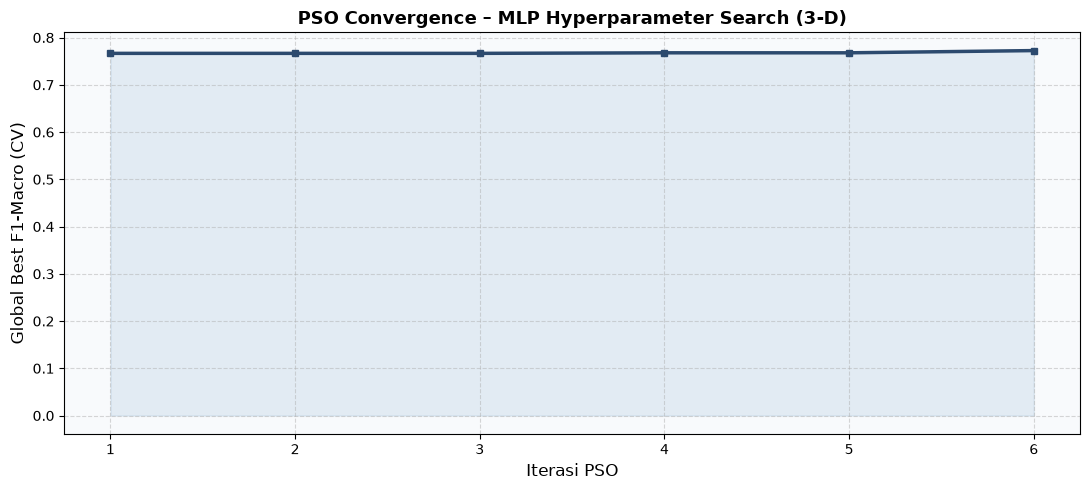

Plot PSO disimpan → plot_pso.png


In [8]:
# Cell 8 – Visualisasi PSO Convergence

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(range(1, len(pso_curve)+1), pso_curve,
        color='#2C4A6E', linewidth=2.5, marker='s', markersize=5)
ax.fill_between(range(1, len(pso_curve)+1), pso_curve, alpha=0.12, color='#4682B4')
ax.set_xlabel('Iterasi PSO', fontsize=12)
ax.set_ylabel('Global Best F1-Macro (CV)', fontsize=12)
ax.set_title('PSO Convergence – MLP Hyperparameter Search (3-D)', fontsize=13, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5); ax.set_facecolor('#F8FAFC')
plt.tight_layout()
plt.savefig('plot_pso.png', dpi=120, bbox_inches='tight')
plt.show()
print('Plot PSO disimpan → plot_pso.png')

In [9]:
# Cell 9 – Eksperimen Pembanding: Model A, B, C, D
# FIX-4: Gunakan print() / to_string() agar berfungsi di script mode (bukan hanya Jupyter)

models = {
    'Model A: Baseline NN':  (MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, random_state=42),
                               X_train_sc, X_test_sc),
    'Model B: GA + NN':      (MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, random_state=42),
                               X_train_ga, X_test_ga),
    'Model C: PSO + NN':     (MLPClassifier(hidden_layer_sizes=(opt_h1, opt_h2),
                               learning_rate_init=opt_lr, max_iter=200, random_state=42),
                               X_train_sc, X_test_sc),
    'Model D: GA + PSO + NN':(MLPClassifier(hidden_layer_sizes=(opt_h1, opt_h2),
                               learning_rate_init=opt_lr, max_iter=200, random_state=42),
                               X_train_ga, X_test_ga),
}

results_list  = []
trained_models = {}

for name, (clf, X_tr, X_te) in models.items():
    clf.fit(X_tr, y_train)
    preds = clf.predict(X_te)
    trained_models[name] = (clf, preds, X_te)
    results_list.append({
        'Konfigurasi Model':  name,
        'Accuracy':           round(accuracy_score(y_test, preds), 4),
        'Precision (Macro)':  round(precision_score(y_test, preds, average='macro', zero_division=0), 4),
        'Recall (Macro)':     round(recall_score(y_test,    preds, average='macro', zero_division=0), 4),
        'F1-Score (Macro)':   round(f1_score(y_test,        preds, average='macro', zero_division=0), 4),
        'F1-Score (Weighted)':round(f1_score(y_test,        preds, average='weighted', zero_division=0), 4),
    })

comparison_df = pd.DataFrame(results_list)

# FIX-4: print() agar bisa dijalankan sebagai script biasa, bukan hanya di Jupyter
print('\n=== Tabel Perbandingan Model ===')
print(comparison_df.set_index('Konfigurasi Model').to_string())

# Juga tampilkan sebagai tabel di Jupyter
try:
    from IPython.display import display
    display(comparison_df)
except ImportError:
    pass


=== Tabel Perbandingan Model ===
                        Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)  F1-Score (Weighted)
Konfigurasi Model                                                                                         
Model A: Baseline NN      0.7609             0.7758          0.7760            0.7743               0.7601
Model B: GA + NN          0.7455             0.7637          0.7395            0.7507               0.7478
Model C: PSO + NN         0.7661             0.7818          0.7738            0.7759               0.7673
Model D: GA + PSO + NN    0.7584             0.7700          0.7503            0.7591               0.7612


,Konfigurasi Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Model A: Baseline NN,0.7609,0.7758,0.7760,0.7743,0.7601
1,Model B: GA + NN,0.7455,0.7637,0.7395,0.7507,0.7478
2,Model C: PSO + NN,0.7661,0.7818,0.7738,0.7759,0.7673
3,Model D: GA + PSO + NN,0.7584,0.7700,0.7503,0.7591,0.7612


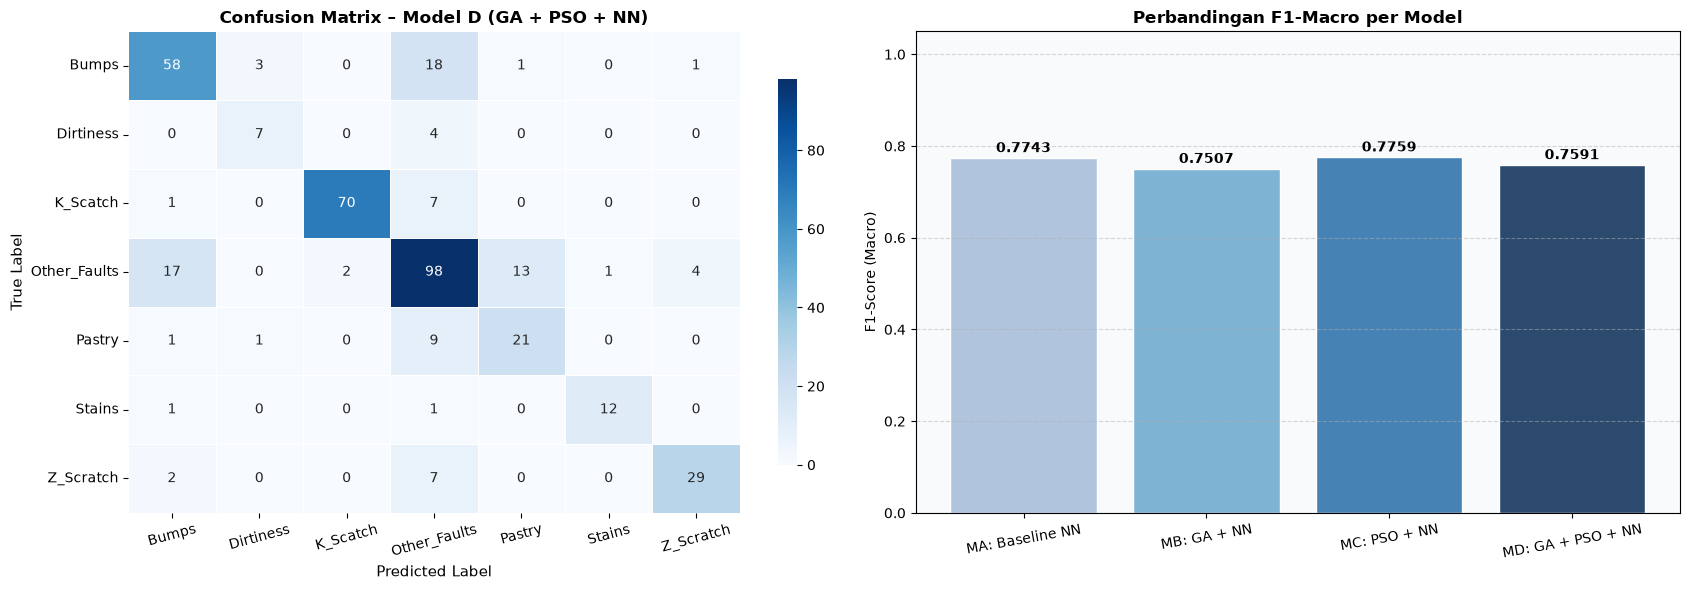


=== Classification Report – Model D ===
              precision    recall  f1-score   support

       Bumps       0.72      0.72      0.72        81
   Dirtiness       0.64      0.64      0.64        11
    K_Scatch       0.97      0.90      0.93        78
Other_Faults       0.68      0.73      0.70       135
      Pastry       0.60      0.66      0.63        32
      Stains       0.92      0.86      0.89        14
   Z_Scratch       0.85      0.76      0.81        38

    accuracy                           0.76       389
   macro avg       0.77      0.75      0.76       389
weighted avg       0.77      0.76      0.76       389



In [10]:
# Cell 10 – Visualisasi: Confusion Matrix & Bar Chart F1-Score

final_clf, final_preds, final_X_te = trained_models['Model D: GA + PSO + NN']
cm = confusion_matrix(y_test, final_preds)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# (a) Confusion matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_,
            linewidths=0.5, ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].set_title('Confusion Matrix – Model D (GA + PSO + NN)', fontweight='bold')
axes[0].tick_params(axis='x', rotation=15)

# (b) Bar chart F1-Macro per model
f1_vals  = comparison_df['F1-Score (Macro)'].values
mod_names = comparison_df['Konfigurasi Model'].str.replace('Model ', 'M').values
bar_colors = ['#B0C4DE', '#7FB3D3', '#4682B4', '#2C4A6E']
bars = axes[1].bar(mod_names, f1_vals, color=bar_colors, edgecolor='white')
for bar, v in zip(bars, f1_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 0.005,
                 f'{v:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[1].set_ylim(0, 1.05); axes[1].set_ylabel('F1-Score (Macro)')
axes[1].set_title('Perbandingan F1-Macro per Model', fontweight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].set_facecolor('#F8FAFC')
axes[1].tick_params(axis='x', rotation=10)

plt.tight_layout()
plt.savefig('plot_model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

# Classification report
print('\n=== Classification Report – Model D ===')
print(classification_report(y_test, final_preds, target_names=le.classes_, zero_division=0))

In [11]:
# Cell 11 – Fuzzy Inference System (Decision Support Layer)
# FIX-2: trapmf/trimf menggunakan max(denominator, eps) tanpa mencampur ke numerator
# FIX-3: X_test_orig digunakan (bukan X_test yang sudah discale)

SEVERITY_MAP = {
    'Stains': 0.35, 'Dirtiness': 0.40, 'Other_Faults': 0.55,
    'Bumps': 0.70,  'Pastry': 0.75,    'Z_Scratch': 0.88, 'K_Scatch': 0.95
}

def trapmf(x, a, b, c, d):
    """FIX-2: Trapezoidal MF – max(denominator, eps) tanpa mempengaruhi numerator."""
    eps = 1e-9
    if x <= a or x >= d: return 0.0
    if b <= x <= c:      return 1.0
    if a < x < b:        return float((x - a) / max(b - a, eps))
    return float((d - x) / max(d - c, eps))

def trimf(x, a, b, c):
    """FIX-2: Triangular MF – max(denominator, eps)."""
    eps = 1e-9
    if x <= a or x >= c: return 0.0
    if x <= b: return float((x - a) / max(b - a, eps))
    return float((c - x) / max(c - b, eps))

def fuzzy_inspection(defect_class, conf, norm_area):
    crit      = SEVERITY_MAP.get(defect_class, 0.55)
    prob_low  = trapmf(conf, 0.0, 0.0, 0.35, 0.55)
    _prob_med = trimf(conf,  0.40, 0.65, 0.85)
    prob_high = trapmf(conf, 0.70, 0.85, 1.0, 1.0)
    area_sm   = trapmf(norm_area, 0.0, 0.0, 0.25, 0.45)
    _area_md  = trimf(norm_area,  0.30, 0.55, 0.75)
    area_lg   = trapmf(norm_area, 0.65, 0.80, 1.0, 1.0)
    r_accept  = min(prob_low,  area_sm) * (1.0 - 0.5 * crit)
    r_reject  = min(prob_high, area_lg) * (0.6 + 0.4 * crit)
    risk      = 0.40 * conf + 0.30 * norm_area + 0.30 * crit
    if r_reject > 0.5:                 risk = max(risk, 0.82)
    elif r_accept > 0.5 and crit < 0.45: risk = min(risk, 0.25)
    if   risk < 0.30: decision = 'Accept'
    elif risk < 0.55: decision = 'Monitor'
    elif risk < 0.78: decision = 'Rework'
    else:             decision = 'Reject'
    return decision, round(float(risk), 4)


probs = final_clf.predict_proba(final_X_te)

# FIX-3: LogOfAreas diambil dari X_test_orig (nilai asli sebelum scaling)
area_min = X_test_orig['LogOfAreas'].min()
area_max = X_test_orig['LogOfAreas'].max()

sim_rows = []
for i in range(min(10, len(final_preds))):
    pred_cls  = le.inverse_transform([final_preds[i]])[0]
    true_cls  = le.inverse_transform([y_test[i]])[0]
    conf      = float(np.max(probs[i]))
    # FIX-3: gunakan X_test_orig (DataFrame asli), bukan X_test_sc (sudah discale)
    raw_area  = float(X_test_orig.iloc[i]['LogOfAreas'])
    norm_area = (raw_area - area_min) / max(area_max - area_min, 1e-9)
    dec, score = fuzzy_inspection(pred_cls, conf, float(norm_area))
    sim_rows.append({
        'Sample_ID':           i + 1,
        'True_Class':          true_cls,
        'Predicted_Defect':    pred_cls,
        'Confidence':          round(conf, 4),
        'LogOfAreas_Norm':     round(float(norm_area), 4),
        'Fuzzy_Risk_Score':    score,
        'Inspection_Priority': dec,
    })

fuzzy_df = pd.DataFrame(sim_rows)
print('=== Hasil Fuzzy Inspection System (10 sampel pertama) ===')
print(fuzzy_df.to_string(index=False))

try:
    from IPython.display import display
    display(fuzzy_df)
except ImportError:
    pass

=== Hasil Fuzzy Inspection System (10 sampel pertama) ===
 Sample_ID   True_Class Predicted_Defect  Confidence  LogOfAreas_Norm  Fuzzy_Risk_Score Inspection_Priority
         1 Other_Faults     Other_Faults      0.7405           0.5099            0.6142              Rework
         2    Dirtiness        Dirtiness      0.4743           0.2393            0.3815             Monitor
         3        Bumps            Bumps      0.9486           0.2911            0.6768              Rework
         4 Other_Faults     Other_Faults      0.5688           0.2858            0.4783             Monitor
         5     K_Scatch         K_Scatch      0.9688           0.2613            0.7509              Rework
         6       Pastry     Other_Faults      0.8814           0.3462            0.6214              Rework
         7     K_Scatch         K_Scatch      0.9869           0.6216            0.8663              Reject
         8 Other_Faults     Other_Faults      0.9619           0.4036         

,Sample_ID,True_Class,Predicted_Defect,Confidence,LogOfAreas_Norm,Fuzzy_Risk_Score,Inspection_Priority
0,1,Other_Faults,Other_Faults,0.7405,0.5099,0.6142,Rework
1,2,Dirtiness,Dirtiness,0.4743,0.2393,0.3815,Monitor
2,3,Bumps,Bumps,0.9486,0.2911,0.6768,Rework
3,4,Other_Faults,Other_Faults,0.5688,0.2858,0.4783,Monitor
4,5,K_Scatch,K_Scatch,0.9688,0.2613,0.7509,Rework
5,6,Pastry,Other_Faults,0.8814,0.3462,0.6214,Rework
6,7,K_Scatch,K_Scatch,0.9869,0.6216,0.8663,Reject
7,8,Other_Faults,Other_Faults,0.9619,0.4036,0.6709,Rework
8,9,Bumps,Bumps,0.7434,0.2364,0.5783,Rework
9,10,Z_Scratch,Z_Scratch,0.5144,0.2202,0.5358,Monitor


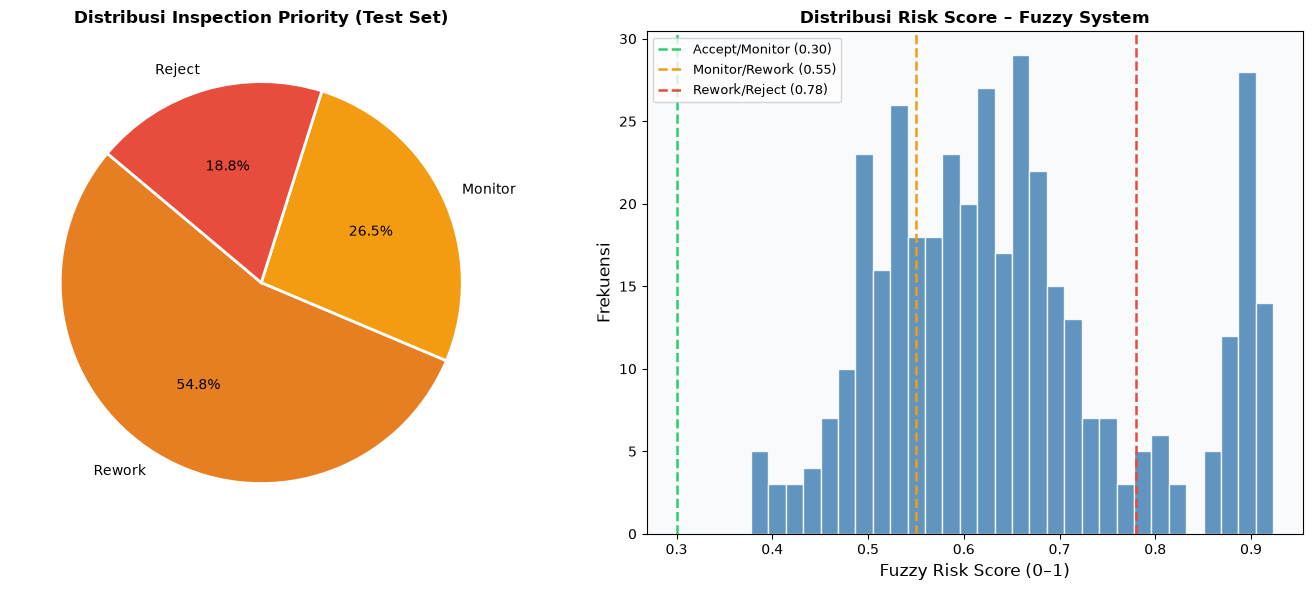

Distribusi Prioritas Inspeksi:
Priority
Rework     213
Monitor    103
Reject      73

Risk Score – Mean: 0.6467 | Std: 0.1354


In [12]:
# Cell 12 – Visualisasi Fuzzy: Pie Chart Prioritas + Distribusi Risk Score

# Jalankan fuzzy pada seluruh test set untuk visualisasi
all_rows = []
for i in range(len(final_preds)):
    pred_cls  = le.inverse_transform([final_preds[i]])[0]
    conf      = float(np.max(probs[i]))
    raw_area  = float(X_test_orig.iloc[i]['LogOfAreas'])
    norm_area = (raw_area - area_min) / max(area_max - area_min, 1e-9)
    dec, score = fuzzy_inspection(pred_cls, conf, float(norm_area))
    all_rows.append({'Priority': dec, 'Risk_Score': score})
all_fuzzy_df = pd.DataFrame(all_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie chart
vc = all_fuzzy_df['Priority'].value_counts()
pie_colors = {'Accept': '#2ECC71', 'Monitor': '#F39C12', 'Rework': '#E67E22', 'Reject': '#E74C3C'}
axes[0].pie(vc.values, labels=vc.index, autopct='%1.1f%%',
            colors=[pie_colors.get(k, '#AAA') for k in vc.index],
            startangle=140, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Distribusi Inspection Priority (Test Set)', fontweight='bold')

# Histogram risk score
axes[1].hist(all_fuzzy_df['Risk_Score'], bins=30, color='#4682B4', edgecolor='white', alpha=0.85)
axes[1].axvline(0.30, color='#2ECC71', linestyle='--', linewidth=1.8, label='Accept/Monitor (0.30)')
axes[1].axvline(0.55, color='#F39C12', linestyle='--', linewidth=1.8, label='Monitor/Rework (0.55)')
axes[1].axvline(0.78, color='#E74C3C', linestyle='--', linewidth=1.8, label='Rework/Reject (0.78)')
axes[1].set_xlabel('Fuzzy Risk Score (0–1)', fontsize=12)
axes[1].set_ylabel('Frekuensi', fontsize=12)
axes[1].set_title('Distribusi Risk Score – Fuzzy System', fontweight='bold')
axes[1].legend(fontsize=9); axes[1].set_facecolor('#F8FAFC')

plt.tight_layout()
plt.savefig('plot_fuzzy.png', dpi=120, bbox_inches='tight')
plt.show()

print('Distribusi Prioritas Inspeksi:')
print(all_fuzzy_df['Priority'].value_counts().to_string())
print(f'\nRisk Score – Mean: {all_fuzzy_df["Risk_Score"].mean():.4f} '
      f'| Std: {all_fuzzy_df["Risk_Score"].std():.4f}')

In [13]:
# Cell 13 – Simpan Artefak Pipeline (FIX-7: model save via joblib)

artifacts = {
    # Preprocessing
    'scaler':              scaler,
    'le':                  le,
    'all_feature_names':   ALL_FEATURES,
    'class_names':         list(le.classes_),
    # GA
    'ga_chromosome':       best_overall_chrom,
    'ga_selected_features':selected_features,
    'ga_feature_freq':     dict(zip(ALL_FEATURES, freq.tolist())),
    'ga_curve':            best_ga_curve,
    'ga_all_results':      ga_all_data,
    # PSO
    'pso_params':          {'h1': opt_h1, 'h2': opt_h2, 'lr': opt_lr},
    'pso_curve':           pso_curve,
    'pso_best_fitness':    best_pso_fit,
    # Models
    'final_model':         final_clf,
    'all_models':          {name: clf for name, (clf, _, __) in trained_models.items()},
    # Evaluation
    'comparison_df':       comparison_df.set_index('Konfigurasi Model'),
    'confusion_matrix':    cm,
    'classification_report': classification_report(y_test, final_preds,
                                                    target_names=le.classes_, zero_division=0),
    # Test data
    'X_test_sc':           X_test_sc,
    'X_test_ga':           X_test_ga,
    'X_test_orig':         X_test_orig,   # ← FIX-3
    'y_test':              y_test,
    # Fuzzy results
    'fuzzy_results_df':    all_fuzzy_df,
}

output_path = 'pipeline_artifacts.pkl'
joblib.dump(artifacts, output_path)
size_kb = os.path.getsize(output_path) / 1024
print(f'✓ Artefak pipeline disimpan → {output_path}  ({size_kb:.1f} KB)')
print('  Jalankan: streamlit run streamlit_dashboard.py')

✓ Artefak pipeline disimpan → pipeline_artifacts.pkl  (1414.5 KB)
  Jalankan: streamlit run streamlit_dashboard.py
